<img src="https://www.anped.org.br/sites/default/files/images/ufcg-lateral.png" width="780" height="240" align="center"/>

## Centro de Engenharia Elétrica e Informática
## Departamento de Engenharia Elétrica
## Disciplina: <span style='color:red'>Int. ao Processamento de Imagem Digital e Visão Computacional</span>
## Professora: <span style='color:red'>Luciana Veloso</span>
## Aluno(a): <span style='color:red'>Alysson Machado de Oliveira Barbosa</span>

# <span style='color:brown'>Experimento 06: Redes Neurais Artificiais</span>
***

## Sumário de Conteúdos

* [0. Importação dos Pacotes](#0)
* [1. Banco de Dados](#1)
* [2. Organização do Banco de Dados](#2)
* [3. Pré-processamento dos Dados](#3)
* [4. Construindo o Modelo](#4)
* [5. Treinando o Modelo](#5)
* [6. Teste do Modelo](#6)
* [7. Referências](#7)

## <span style='color:brown'>0. Importação dos Pacotes</span> <a class="anchor" id="0"></a>
***

In [96]:
import os                                             # Operational System para manipulação de arquivos.
import cv2                                            # OpenCV para manipulação de imagens.
import numpy as np                                    # Numpy para manipulação de matrizes e arrays.
import matplotlib.pyplot as plt                       # Pyplot para plotagem de gráficos e imagens.
from sklearn.model_selection import train_test_split  # Função para particionamento dos dados

from tensorflow.keras.models import Sequential        # Classe de modelos sequenciais para construir as redes neurais.
from tensorflow.keras.layers import Dense, Input, Dropout      # Camada de neurônios densamente conectados.
from tensorflow.keras.optimizers import SGD           # Otimizador "Descida do Gradiente com Momento".
from tensorflow.keras.datasets import boston_housing  # Dataset utilizado nesse experimento.

## <span style='color:brown'>1. Banco de Dados</span> <a class="anchor" id="1"></a>
***
* Vamos utilizar um banco de dados do catálogo de datasets do Keras, que é disponibilizado como uma função pronta;

* Cada instância do banco de dados corresponde a um conjunto de 13 valores referentes a características de subúrbios de Boston na década de 1970, a exemplo de taxa de crimes, imposto sobre propriedade, etc;

* Esses valores serão utilizados para calcular o valor mediano das residências no respectivo subúrbio em um problema de regressão, de modo que iremos mapear um vetor de entrada com 13 valores em um vetor de saída com 1 único elemento;

* O banco de dados contém 506 valores divididos em 404 instâncias de treino e 102 de teste;

* Uma descrição mais detalhada dos valores de entrada pode ser vista em http://lib.stat.cmu.edu/datasets/boston, onde os valores são descritos na ordem que aparecem;

## <span style='color:brown'>2. Organização do banco de dados</span> <a class="anchor" id="2"></a>
***
* Comumente os dados utilizados no treinamento de modelos de inteligência artificial reservam a primeira dimensão para controlar a amostra e espalham o tipo de dado utilizado nas demais dimensões do tensor. 


* Nesse caso, os nossos dados são vetores de características unidimensionais (1D), de modo que são organizados em tensores bidimensionais (2D) com formato: **dados.shape = (amostras, características)**
    * O i-ésimo exemplo pode ser acessado a partir de: **exemplo = dados[i]**
    * A j-ésima característica dos exemplos pode ser acessada a partir de: **caracteristica = dados[:, j]**
    * Porções do tensor podem ser acessadas utilizando fatiamento, por exemplo:
        * primeiros_5_exemplos = dados[:5]
        * caracteristicas_9a13 = dados[8:13]
        

* Lembrem-se que a contagem de índices em Python começa em 0 e só é inclusiva no primeiro elemento:
    * **:5** produz os índices **0, 1, 2, 3, 4** 
    * **8:13** produz os índices **8, 9, 10, 11, 12** 
        

* O banco de dados pode ser carregado utilizando:
    * **(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()**
    * train_data é um tensor com as entradas do conjunto de treino;
    * test_data é um tensor com as entradas do conjunto de teste;
    * train_targets é um tensor com os gabaritos do conjunto de treino;
    * test_targets é um tensor com os gabaritos do conjunto de teste;

* <span style='color:blue'>**a. O código abaixo carrega o banco de dados, acesse alguns exemplos de treinamento e de teste e veja suas dimensões.**</span>

    * <span style='color:blue'>Use índices entre **[0, 404]** para os dados de treino e entre **[0, 102]** para os de teste.</span>

In [117]:
(train_data, train_targets), (test_data, test_targets) = boston_housing.load_data()

In [118]:
print('Dimensão dos Dados de Treinamento: ', train_data.shape)
print('Dimensão dos Rótulos nos Dados de Treinamento: ', train_targets.shape)
print('Dimensão dos Dados de Teste: ', test_data.shape)
print('Dimensão dos Rótulos nos Dados de Teste: ', test_targets.shape)

Dimensão dos Dados de Treinamento:  (404, 13)
Dimensão dos Rótulos nos Dados de Treinamento:  (404,)
Dimensão dos Dados de Teste:  (102, 13)
Dimensão dos Rótulos nos Dados de Teste:  (102,)


In [119]:
print('Exemplo dos Dados de Entrada:\n', train_data[0])
print('\nExemplo dos Dados de Saída:\n', train_targets[0])

Exemplo dos Dados de Entrada:
 [  1.23247   0.        8.14      0.        0.538     6.142    91.7
   3.9769    4.      307.       21.      396.9      18.72   ]

Exemplo dos Dados de Saída:
 15.2


* <span style='color:blue'>**b. Verifique as dimensões e as faixas de valores de cada característica nos vetores de entrada dos conjuntos de treino e de teste. A faixa de valores das características são semelhantes? E os dados de treino e de teste?**</span>

    * <span style='color:blue'>Encontre os valores mínimo/máximo além da média **(np.mean)** e da variância **(np.var)** de cada uma das 13 características.
    * <span style='color:blue'>Sugestão: leia sobre o parâmetro "axis" na documentação das funções **np.min**, **np.max** e **np.mean**.

|**Características dos Dados de Entrada**|**Descrição**|
|:-:|:-|
|**CRIM**|     <span style='color:red'>per capita crime rate by town</span>|
|**ZN**|       <span style='color:red'>proportion of residential land zoned for lots over 25,000 sq.ft.</span>|
|**INDUS**|    <span style='color:red'>proportion of non-retail business acres per town</span>|
|**CHAS**|     <span style='color:red'>Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)</span>|
|**NOX**|      <span style='color:red'>nitric oxides concentration (parts per 10 million)</span>|
|**RM**|       <span style='color:red'>average number of rooms per dwelling</span>|
|**AGE**|      <span style='color:red'>proportion of owner-occupied units built prior to 1940</span>|
|**DIS**|      <span style='color:red'>weighted distances to five Boston employment centres</span>|
|**RAD**|      <span style='color:red'>index of accessibility to radial highways</span>|
|**TAX**|      <span style='color:red'>full-value property-tax rate per \$10,000</span>|
|**PTRATIO**|  <span style='color:red'>pupil-teacher ratio by town</span>|
|**B**|        <span style='color:red'>$1000(B_k - 0.63)^2$ where Bk is the proportion of blacks by town</span>|
|**LSTAT**|    <span style='color:red'>\% lower status of the population</span>|

In [120]:
min_train_x = np.min(train_data, axis=0)
max_train_x = np.max(train_data, axis=0)
mean_train_x = np.mean(train_data, axis=0)
var_train_x = np.var(train_data, axis=0)

for i in range(1,14):
    print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(i,min_train_x[i-1], 
                                                                                     max_train_x[i-1],
                                                                                     mean_train_x[i-1], 
                                                                                     var_train_x[i-1]))

1 - Limite: [0.01,88.98], com Média 3.75 e Variância 85.18
2 - Limite: [0.00,100.00], com Média 11.48 e Variância 563.51
3 - Limite: [0.46,27.74], com Média 11.10 e Variância 46.28
4 - Limite: [0.00,1.00], com Média 0.06 e Variância 0.06
5 - Limite: [0.39,0.87], com Média 0.56 e Variância 0.01
6 - Limite: [3.56,8.72], com Média 6.27 e Variância 0.50
7 - Limite: [2.90,100.00], com Média 69.01 e Variância 778.75
8 - Limite: [1.13,10.71], com Média 3.74 e Variância 4.11
9 - Limite: [1.00,24.00], com Média 9.44 e Variância 75.47
10 - Limite: [188.00,711.00], com Média 405.90 e Variância 27611.97
11 - Limite: [12.60,22.00], com Média 18.48 e Variância 4.83
12 - Limite: [0.32,396.90], com Média 354.78 e Variância 8834.99
13 - Limite: [1.73,37.97], com Média 12.74 e Variância 52.50


In [121]:
min_test_x = np.min(test_data, axis=0)
max_test_x = np.max(test_data, axis=0)
mean_test_x = np.mean(test_data, axis=0)
var_test_x = np.var(test_data, axis=0)

for i in range(1,14):
    print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(i,min_test_x[i-1], 
                                                                                     max_test_x[i-1],
                                                                                     mean_test_x[i-1], 
                                                                                     var_test_x[i-1]))

1 - Limite: [0.01,25.05], com Média 3.09 e Variância 28.59
2 - Limite: [0.00,90.00], com Média 10.90 e Variância 460.83
3 - Limite: [1.22,27.74], com Média 11.26 e Variância 49.69
4 - Limite: [0.00,1.00], com Média 0.10 e Variância 0.09
5 - Limite: [0.39,0.87], com Média 0.54 e Variância 0.01
6 - Limite: [4.88,8.78], com Média 6.35 e Variância 0.45
7 - Limite: [6.00,100.00], com Média 66.85 e Variância 834.77
8 - Limite: [1.47,12.13], com Média 4.01 e Variância 5.61
9 - Limite: [1.00,24.00], com Média 9.98 e Variância 76.20
10 - Limite: [187.00,711.00], com Média 417.50 e Variância 31158.88
11 - Limite: [13.00,21.20], com Média 18.37 e Variância 4.07
12 - Limite: [24.65,396.90], com Média 364.16 e Variância 6201.47
13 - Limite: [1.92,31.99], com Média 12.31 e Variância 44.39


* <span style='color:green'> Observando a faixa de valores estatísticos mínimos, máximos, média e variância para cada uma das caraterísticas, tanto nos dados de treinamento quanto nos dados de teste, podemos perceber duas principais características entre esses valores:</span>
* <span style='color:green'>a. Os valores estatísticos variam entre cada uma das características, isso ocorre devido a distinção das características, já que cada uma delas indica parâmetros distintos sobre os subúrbios de Boston;</span>
* <span style='color:green'>b. Comparando as características dos dados de treinamento e dos dados de teste, é perceptível que ambos possuem o mesmo grau de estratíficação, mas correspondem a dados distintos;</span>

* <span style='color:blue'>**c. Verifique as dimensões e as faixas de valores dos gabaritos dos conjuntos de treino e de teste. Os valores encontrados são semelhantes?**</span>

|**Características dos Dados de Saída**|**Descrição**|
|:-:|:-|
|**MEDV**|     <span style='color:red'>Median value of owner-occupied homes in \$1000's</span>|

In [122]:
min_train_x = np.min(train_targets, axis=0)
max_train_x = np.max(train_targets, axis=0)
mean_train_x = np.mean(train_targets, axis=0)
var_train_x = np.var(train_targets, axis=0)

print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(14, min_train_x, 
                                                                                     max_train_x,
                                                                                     mean_train_x, 
                                                                                     var_train_x))

14 - Limite: [5.00,50.00], com Média 22.40 e Variância 84.62


In [123]:
min_train_x = np.min(test_targets, axis=0)
max_train_x = np.max(test_targets, axis=0)
mean_train_x = np.mean(test_targets, axis=0)
var_train_x = np.var(test_targets, axis=0)

print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(14, min_train_x, 
                                                                                     max_train_x,
                                                                                     mean_train_x, 
                                                                                     var_train_x))

14 - Limite: [5.60,50.00], com Média 23.08 e Variância 83.24


* <span style='color:green'> As mesmas considerações feitas na (1.1-b) podem ser generalizadas para os Rótulos de Treinamento e Teste, a única diferença é que há apenas uma característica a ser predita pelo modelo.</span>

## <span style='color:brown'>3. Pre-processamento dos dados</span> <a class="anchor" id="3"></a>
***

* Dados cujas características assumem diferentes faixas de valores muitas vezes são problemáticos para o aprendizado dos modelos e podem reduzir a velocidade de convergência ou até mesmo limitar as capacidades do modelo final.

* Nesse sentido, uma prática comum é a normalização dos dados antes do treinamento, que geralmente é feito por característica em forma da subtração da média e divisão pelo desvio padrão, o que faz com que os dados resultantes tenham média 0 e variância 1.

* Um ponto muito importante é que a normalização deve ser feita partir dos mesmos valores em todos os conjuntos, ou seja, os dados são normalizados segundo informações do conjunto de treino.

* Na prática não temos como calcular a média e variância real, mas se os dados de treino são significativos os seus valores são suficientes.

In [124]:
# Calcula a média do conjunto de treino
mean = train_data.mean(axis=0)

# Calcula o desvio padrão do conjunto de treino
std = train_data.std(axis=0)

# Normaliza os dados de treino
train_data -= mean
train_data /= std

# Normaliza os dados de teste
test_data -= mean
test_data /= std

* <span style='color:blue'>**d. Repita o item b para os dados normalizados. O que se observa quantos aos valores de média e variância para os dados de treino e teste? Comente a sua interpretação sobre as diferenças observadas.**</span>

In [125]:
min_train_x = np.min(train_data, axis=0)
max_train_x = np.max(train_data, axis=0)
mean_train_x = np.mean(train_data, axis=0)
var_train_x = np.var(train_data, axis=0)

for i in range(1,14):
    print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(i,min_train_x[i-1], 
                                                                                     max_train_x[i-1],
                                                                                     mean_train_x[i-1], 
                                                                                     var_train_x[i-1]))

1 - Limite: [-0.41,9.23], com Média -0.00 e Variância 1.00
2 - Limite: [-0.48,3.73], com Média 0.00 e Variância 1.00
3 - Limite: [-1.56,2.45], com Média 0.00 e Variância 1.00
4 - Limite: [-0.26,3.89], com Média -0.00 e Variância 1.00
5 - Limite: [-1.47,2.68], com Média -0.00 e Variância 1.00
6 - Limite: [-3.82,3.47], com Média 0.00 e Variância 1.00
7 - Limite: [-2.37,1.11], com Média 0.00 e Variância 1.00
8 - Limite: [-1.29,3.44], com Média 0.00 e Variância 1.00
9 - Limite: [-0.97,1.68], com Média 0.00 e Variância 1.00
10 - Limite: [-1.31,1.84], com Média -0.00 e Variância 1.00
11 - Limite: [-2.67,1.60], com Média 0.00 e Variância 1.00
12 - Limite: [-3.77,0.45], com Média 0.00 e Variância 1.00
13 - Limite: [-1.52,3.48], com Média 0.00 e Variância 1.00


In [126]:
min_test_x = np.min(test_data, axis=0)
max_test_x = np.max(test_data, axis=0)
mean_test_x = np.mean(test_data, axis=0)
var_test_x = np.var(test_data, axis=0)

for i in range(1,14):
    print('{} - Limite: [{:.2f},{:.2f}], com Média {:.2f} e Variância {:.2f}'.format(i,min_test_x[i-1], 
                                                                                     max_test_x[i-1],
                                                                                     mean_test_x[i-1], 
                                                                                     var_test_x[i-1]))

1 - Limite: [-0.40,2.31], com Média -0.07 e Variância 0.34
2 - Limite: [-0.48,3.31], com Média -0.02 e Variância 0.82
3 - Limite: [-1.45,2.45], com Média 0.02 e Variância 1.07
4 - Limite: [-0.26,3.89], com Média 0.15 e Variância 1.52
5 - Limite: [-1.41,2.68], com Média -0.11 e Variância 0.87
6 - Limite: [-1.96,3.54], com Média 0.12 e Variância 0.89
7 - Limite: [-2.26,1.11], com Média -0.08 e Variância 1.07
8 - Limite: [-1.12,4.14], com Média 0.13 e Variância 1.36
9 - Limite: [-0.97,1.68], com Média 0.06 e Variância 1.01
10 - Limite: [-1.32,1.84], com Média 0.07 e Variância 1.13
11 - Limite: [-2.49,1.24], com Média -0.05 e Variância 0.84
12 - Limite: [-3.51,0.45], com Média 0.10 e Variância 0.70
13 - Limite: [-1.49,2.66], com Média -0.06 e Variância 0.85


- **Método de Normalização Utilizada**: $$\hat{X} = \frac{X - \mu}{\sigma}$$

* <span style='color:green'>Analisando os valores estatísticos com os Dados Normalizados, é perceptível que o valor médio de cada uma das características foi configurada como 0 e a variância como 1 nos Dados de Treinamento. Essas técnicas permitem, além de reduzir o custo computacional na hora de treinar modelos com dados normalizados, destacam com mais qualidade as características sem alterar a sua essência. Utilizando a média e a variância obtida com os Dados de Treinamento, os Dados de Teste foram normalizados, mas apresentam valores médios e de variância um pouco distintos de 0 e 1, respectivamente. Esse tipo de configuração é ideal para tornar os dados de teste mais próximos dos dados de treinamento de forma automatizada, permitindo um melhor resultado nas métricas de avaliação.</span> 

Agora vamos criar uma partição de validação a partir do conjunto de treino para realizar uma validação cruzada. Vamos utilizar a função **train_test_split**, que separa dados e os seus respectivos gabaritos segundo uma fração especificada.

In [127]:
# Fração escolhida para separar o mesmo número de instâncias do conjunto de testes
data_frac = test_data.shape[0] / train_data.shape[0]

# Criação do conjunto de validação
train_data, val_data, train_targets, val_targets = train_test_split(train_data,             # Dados de treino
                                                                    train_targets,          # Gabaritos de treino
                                                                    test_size = data_frac,  # Proporção de dados p/ validação
                                                                    random_state=42)        # Semente para garantir consistencia nos resultados

print("Treino:", train_data.shape, train_targets.shape)
print("Validação:", val_data.shape, val_targets.shape)

Treino: (302, 13) (302,)
Validação: (102, 13) (102,)


## <span style='color:brown'>4. Construindo o modelo</span> <a class="anchor" id="4"></a>
*** 

Para construir o modelo usaremos a classe **Sequential**, que possibilita a construção de modelos sequenciais de forma bastante simples.
* A construção do modelo é feita a partir do seu instanciamento como objeto da classe seguido de chamadas à função **add()** para adicionar camadas.
* Como estamos construindo apenas Redes Neurais Artificiais por enquanto, vamos utilizar apenas as camadas **Dense** e **Input**.
    * A camada Input cria a entrada da rede com **Input( shape = None )**
        * shape corresponde ao formato do tensor de entrada, no nosso caso será o número de características do nosso banco de dados (13);
    * A camada Dense pode ser chamada com **Dense( n_unidades, activation = 'linear' )**
        * n_unidades corresponde ao número de neurônios da camada;
        * activation corresponde à função de ativação utilizada na camada;
* Algumas funções de ativação disponíveis são:
    * "linear"
    * "relu"
    * "sigmoid"
    * "softmax"
    * "tanh"


* Mais informações sobre a camada dense podem ser vistas em **https://keras.io/api/layers/core_layers/dense/**
* Mais informações sobre as ativações disponíveis podem ser vistas em **https://keras.io/api/layers/activations/**

* <span style='color:blue'>**e. A função abaixo constroi um modelo de rede neural e utiliza a função summary() para apresentar um resumo das informações da rede neural produzida. Comente o que faz cada linha do código.**</span>
    * <span style='color:blue'>Modifique parâmetros como o número de unidades de cada camada e/ou o formato do tensor de entrada e/ou o número de saídas.</span> 
    * <span style='color:blue'>Explique como o número de parâmetros de cada camada é calculado.</span>

In [85]:
def build_model( n_inputs, n_outputs ):
    # instanciando a construção do modelo de forma sequencial
    rede = Sequential()
    # adicionando uma camada densa com 64 neurônios e função de ativação relu
    # essa camada procede uma camada de entrada com n_inputs neurônios  
    rede.add( Dense(units = 64, activation = "relu", input_shape = (n_inputs,)))
    # adicionando uma camada densa com 64 neurônios e função de ativação relu
    rede.add(Dense(units = 64, activation = "relu"))
    # adicionando uma camada densa de saida com n_outputs neurônios e função de ativação linar 
    rede.add(Dense(units = n_outputs ))
    return rede

model = build_model(13, 1)
model.summary()

Model: "sequential_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_6 (Dense)              (None, 64)                896       
_________________________________________________________________
dense_7 (Dense)              (None, 64)                4160      
_________________________________________________________________
dense_8 (Dense)              (None, 1)                 65        
Total params: 5,121
Trainable params: 5,121
Non-trainable params: 0
_________________________________________________________________


* <span style='color:green'>A explicação do código acima foi adicionada como forma de comentário dentro do código.
</span> 

* <span style='color:blue'>**f. Nesse caso utilizamos uma saída com ativação linear. Qual seria a desvantagem de utilizar esse tipo de ativação nas demais camadas?**</span>

* <span style='color:green'>A razão para não usar a função de ativação linear nas camadas ocultas é que não é possível usar a retropropagação (gradiente descendente) para treinar o modelo - a derivada da função é uma constante e não tem relação com a entrada X. Portanto, não é possível fazer o "caminho de volta" e entender quais pesos nos neurônios de entrada podem fornecer uma previsão melhor.</span> 

Após a construção do modelo ele deve ser compilado antes que os parâmetros sejam treinados. Isso é feito utilizando a função **compile**:

* **model.compile( optimizer = opt, loss = fperdas, metrics = [] )** 
    * O optimizer é o algoritmo otimizador utilizado no lugar da descida do gradiente, o Keras oferece diversas opções;
        * Para treinar a partir da descida do gradiente utilizaremos o SGD (descida do gradiente com momento), mas setaremos esse parâmetro para 0.
        * **opt = SGD( learning_rate = taxa_de_aprendizagem, momentum = 0 )**
    * A função de perdas pode ser definida a partir do parâmetro loss, como este é um problema de regressão utilizaremos o erro médio quadrático: 
        * **loss = "mse"**
    * Podemos passar uma lista de métricas a serem computadas durante o treinamento, nesse caso utilizaremos o erro médio absoluto:
        * **metrics = ["mae"]**
        * Note que estamos passando uma lista com uma única métrica, mas outras poderiam ser adicionadas à lista.
         
         

* Algoritmos otimizadores populares são o Adam (**https://keras.io/api/optimizers/adam/**) e o RMSprop(**https://keras.io/api/optimizers/rmsprop/**)
* Mais informações sobre os otimizadores disponíveis podem ser vistas em **https://keras.io/api/optimizers/**
* Mais informações sobre as funções de perdas disponíveis podem ser vistas em **https://keras.io/api/losses/**
* Mais informações sobre as métricas disponíveis podem ser vistas em **https://keras.io/api/metrics/**



In [86]:
model = build_model(13, 1)
model.compile( optimizer = SGD(learning_rate=0.001, momentum=0.0), loss = "mse", metrics=["mae"] )
model.summary()

Model: "sequential_3"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_9 (Dense)              (None, 64)                896       
_________________________________________________________________
dense_10 (Dense)             (None, 64)                4160      
_________________________________________________________________
dense_11 (Dense)             (None, 1)                 65        
Total params: 5,121
Trainable params: 5,121
Non-trainable params: 0
_________________________________________________________________


## <span style='color:brown'>5. Treinando o modelo</span> <a class="anchor" id="5"></a>
***

O treinamento é realizado a partir da função **fit**, que recebe dados de treino e de validação além de hiperparâmetros como o número de épocas e o tamanho dos lotes de dados (batchsize).

* **hist = model.fit( x = None, y = None, epochs = 1, batchsize = None, validation_data = None, verbose = "auto")**
    * x corresponde aos dados de treino;
    * y corresponde aos gabaritos de treino;
    * epochs corresponde ao número de épocas de treinamento;
    * batchsize corresponde ao tamanho dos lotes entregues à rede de cada vez;
    * validation_data corresponde a uma tupla ( val_data, val_targets ) com os dados de validação;
    * verbose indica como a função deve reportar os resultados:
        * 0: modo silencioso, nenhum retorno em formato de texto;
        * 1: retorno a cada época e barra de progresso;
        * 2: retorno a cada época sem barra de progresso;
    * hist é um dicionário de retorno com os valores de loss e das métricas computadas para treino e validação;

In [87]:
hist = model.fit( x = train_data, 
                  y = train_targets, 
                  epochs = 100, 
                  batch_size = 1, 
                  validation_data = ( val_data, val_targets ), 
                  verbose = 1)

Epoch 1/100
302/302 [==============================] - 1s 2ms/step - loss: 82.2037 - mae: 6.2503 - val_loss: 41.2655 - val_mae: 5.0651
Epoch 2/100
302/302 [==============================] - 0s 1ms/step - loss: 45.2517 - mae: 4.5980 - val_loss: 86.9843 - val_mae: 6.6805
Epoch 3/100
302/302 [==============================] - 0s 1ms/step - loss: 26.8886 - mae: 3.6823 - val_loss: 13.0679 - val_mae: 2.8447
Epoch 4/100
302/302 [==============================] - 0s 1ms/step - loss: 22.6237 - mae: 3.3930 - val_loss: 33.0379 - val_mae: 3.7174
Epoch 5/100
302/302 [==============================] - 0s 1ms/step - loss: 22.0802 - mae: 3.3163 - val_loss: 11.7177 - val_mae: 2.5852
Epoch 6/100
302/302 [==============================] - 1s 3ms/step - loss: 23.0312 - mae: 3.1992 - val_loss: 23.2344 - val_mae: 3.7941
Epoch 7/100
302/302 [==============================] - 1s 2ms/step - loss: 20.4794 - mae: 3.2779 - val_loss: 36.0533 - val_mae: 5.1977
Epoch 8/100
302/302 [==============================] - 

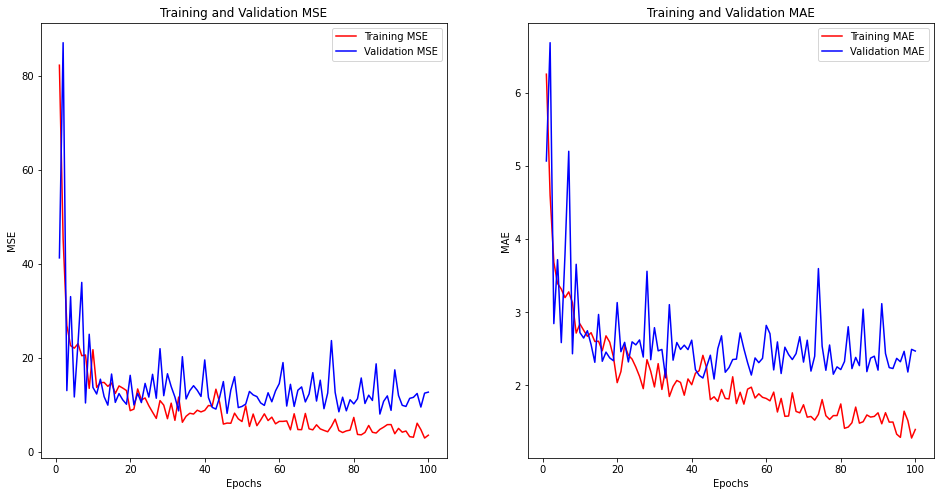

In [95]:
# Plotando os resultados obtidos
fig, axes = plt.subplots(1, 2, squeeze = False, figsize = (16,8))

history_dict = hist.history

# Loss - MSE
train_loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]

# Epochs
epochs = range(1, len(train_loss_values) + 1)

# Metrica - MAE
train_mae_values = history_dict["mae"]
val_mae_values = history_dict["val_mae"]

ax = axes.flat[0]
ax.plot(epochs, train_loss_values, "r", label = "Training MSE")
ax.plot(epochs, val_loss_values, "b", label = "Validation MSE")
ax.set_title("Training and Validation MSE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.legend()

ax = axes.flat[1]
ax.plot(epochs, train_mae_values, "r", label="Training MAE")
ax.plot(epochs, val_mae_values, "b", label="Validation MAE")
ax.set_title("Training and Validation MAE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MAE")
ax.legend()

* <span style='color:blue'>**g. Comente os resultados obtidos nos gráficos acima. Houve overfitting? Se sim, o que pode ser feito para melhorar a qualidade do modelo?**</span>

* <span style='color:green'>Observando o gráfico acima, Tanto o valor de **MSE** quanto no valor de **MAE**, os resultadados nos dados de Validação foram inferiores em relação aos Dados de Treinamento. Desse modo, há um indício de Sobreajuste (*Overfitting*) com os Dados de Treinamento. Alguns fatores podem ser considerados na hora de reduzir o sobreajuste do modelo, são eles:</span>
    * <span style='color:green'>a. Aumentar a quantidade de Dados de Treinamento, considerando dados mais representativos;</span>
    * <span style='color:green'>c. Utilizar técnicas de Dropout para zerar alguns neurônios da camada de forma intensional;</span>
    * <span style='color:green'>d. Reduzir o número de neurônios utilizados nas camadas ocultas; </span>

* <span style='color:blue'>**h. Modifique hiperparâmetros do modelo como o número de camadas, as funções de ativação, o número de épocas utilizadas e o tamanho dos lotes. Comente os resultados obtidos a partir das mudanças realizadas.**</span>

In [110]:
def build_model( n_inputs, n_outputs ):
    
    # instanciando a construção do modelo de forma sequencial
    rede = Sequential()
    # adicionando uma camada densa com 64 neurônios e função de ativação relu
    # essa camada procede uma camada de entrada com n_inputs neurônios  
    rede.add(Dense(units = 64, activation = "relu", input_shape = (n_inputs,)))
    # adicionando uma camada densa com 64 neurônios e função de ativação relu
    rede.add(Dense(units = 64, activation = "relu"))
    # adicionando uma camada de dropout para zerar 20% dos neurônios da camda precessora 
    rede.add(Dropout(rate=0.2))
    # adicionando uma camada densa de saida com n_outputs neurônios e função de ativação linar 
    rede.add(Dense(units = n_outputs))
    
    return rede

model = build_model(13, 1)
model.compile( optimizer = SGD(learning_rate=0.001, momentum=0.0), loss = "mse", metrics=["mae"] )

hist = model.fit( x = train_data, 
                  y = train_targets, 
                  epochs = 100, 
                  batch_size = 4, 
                  steps_per_epoch = len(train_data) // 4,
                  validation_data = ( val_data, val_targets ), 
                  verbose = 1)

Epoch 1/100
75/75 [==============================] - 1s 7ms/step - loss: 137.5819 - mae: 8.3193 - val_loss: 17.5061 - val_mae: 3.0034
Epoch 2/100
75/75 [==============================] - 0s 2ms/step - loss: 30.7658 - mae: 4.0493 - val_loss: 18.4444 - val_mae: 3.3658
Epoch 3/100
75/75 [==============================] - 0s 2ms/step - loss: 29.3858 - mae: 3.9016 - val_loss: 15.2874 - val_mae: 2.8639
Epoch 4/100
75/75 [==============================] - 0s 2ms/step - loss: 22.3710 - mae: 3.4883 - val_loss: 9.9012 - val_mae: 2.3825
Epoch 5/100
75/75 [==============================] - 0s 2ms/step - loss: 21.8400 - mae: 3.3160 - val_loss: 13.6058 - val_mae: 2.6634
Epoch 6/100
75/75 [==============================] - 0s 2ms/step - loss: 22.6164 - mae: 3.4623 - val_loss: 12.8072 - val_mae: 2.8016
Epoch 7/100
75/75 [==============================] - 0s 2ms/step - loss: 24.5453 - mae: 3.7047 - val_loss: 11.1327 - val_mae: 2.6855
Epoch 8/100
75/75 [==============================] - 0s 2ms/step - lo

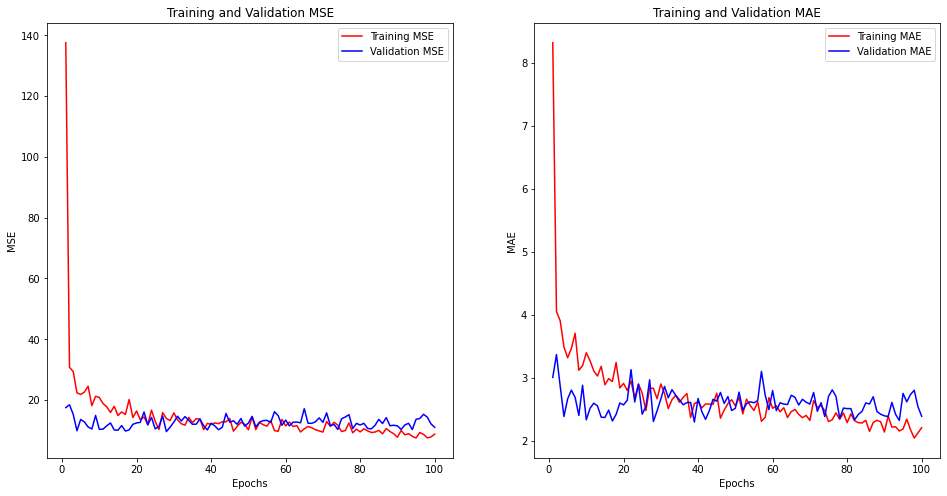

In [111]:
# Plotando os resultados obtidos
fig, axes = plt.subplots(1, 2, squeeze = False, figsize = (16,8))

history_dict = hist.history

# Loss - MSE
train_loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]

# Epochs
epochs = range(1, len(train_loss_values) + 1)

# Metrica - MAE
train_mae_values = history_dict["mae"]
val_mae_values = history_dict["val_mae"]

ax = axes.flat[0]
ax.plot(epochs, train_loss_values, "r", label = "Training MSE")
ax.plot(epochs, val_loss_values, "b", label = "Validation MSE")
ax.set_title("Training and Validation MSE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MSE")
ax.legend()

ax = axes.flat[1]
ax.plot(epochs, train_mae_values, "r", label="Training MAE")
ax.plot(epochs, val_mae_values, "b", label="Validation MAE")
ax.set_title("Training and Validation MAE")
ax.set_xlabel("Epochs")
ax.set_ylabel("MAE")
ax.legend()

* <span style='color:green'>Observando o histórico de treinamento acima, é perceptível que o sobreajuste foi minizado através de algumas mudanças nos hiperparâmetros do modelo. Ou seja, as funções de erro nos Dados de Validação foram minimizados e ficaram aproximadamente semelhante aos valores obtidos com os Dados de Treinamemento. Além disso, podemos considerar que esse ganho é uma forma de tornar a rede mais generalista, em que ela consegue obter previsões mais satisfatórios em dados que distoam dos utilizados no Treinamento do modelo.</span>

## <span style='color:brown'>6. Teste do modelo</span> <a class="anchor" id="6"></a>
***

O teste do modelo pode ser realizado a partir da função **evaluate**, que recebe os dados de treino e retorna o valor de loss calculado para esse conjunto e os valores de cada métrica da lista fornecida durante a compilação do modelo. 

* É uma prática comum realizar ajustes no modelo com base no conjunto de validação e só utilizar o conjunto de testes após a definição dos hiperparâmetros definitivos.
* Como os hiperparâmetros são ajustados a partir dos resultados obtidos para o conjunto de validação, o modelo pode acabar. sobreajustando aos dados de validação, então é interessante mudar os dados desse conjunto com frequência.
* Para mudar os dados de validação basta alterar a semente na função train_test_split.
* Crie um novo modelo do zero após a realização de mudanças nos conjuntos de treino/validação.

In [112]:
test_mse, test_mae = model.evaluate( test_data, test_targets)

# Observa-se que os dados de saída são normalizados em milhares de dólares, 
# então é necessário multiplicar por 1000 para obter os valores absolutos
print("Erro médio absoluto de teste: ${:.2f}".format(1000*test_mae))

4/4 [==============================] - 0s 1ms/step - loss: 17.7087 - mae: 2.7566
Erro médio absoluto de teste: $2756.60


* <span style='color:blue'>**i. Verifique novamente a faixa de valores dos gabaritos no banco de dados. Considerando a extensão dessa faixa de valores, pode-se dizer que as predições do modelo são significativas?**</span>

In [116]:
min_train_x = np.min(train_targets, axis=0)
max_train_x = np.max(train_targets, axis=0)
mean_train_x = np.mean(train_targets, axis=0)
var_train_x = np.var(train_targets, axis=0)

print('{} - Limite: [${:.2f}, ${:.2f}], com Média ${:.2f} e Variância {:.2f}'.format(14, min_train_x*1000, 
                                                                                     max_train_x*1000,
                                                                                     mean_train_x*1000, 
                                                                                     var_train_x))

min_train_x = np.min(test_targets, axis=0)
max_train_x = np.max(test_targets, axis=0)
mean_train_x = np.mean(test_targets, axis=0)
var_train_x = np.var(test_targets, axis=0)

print('{} - Limite: [${:.2f}, ${:.2f}], com Média ${:.2f} e Variância {:.2f}'.format(14, min_train_x*1000, 
                                                                                     max_train_x*1000,
                                                                                     mean_train_x*1000, 
                                                                                     var_train_x))
print("Erro médio absoluto de teste: ${:.2f}".format(1000*test_mae))

14 - Limite: [$5000.00, $50000.00], com Média $22868.54 e Variância 90.36
14 - Limite: [$5600.00, $50000.00], com Média $23078.43 e Variância 83.24
Erro médio absoluto de teste: $2756.60


* <span style='color:green'>Observando os valores médios obtidos nos Dados de Treinamento e nos Dados de Teste em comparação com o erro médio absoluto com os Dados de Teste (previsão do algoritmo), e analisando esses valores com os limites obtidos nos Dados de Treino e Teste, fica perceptível que as predições realizadas pelo algoritmo estão consistentes com os dados de referência utilizados, un indício de que o modelo desenvolvido não apresenta erros durante o desenvolvimento. Além disso, o baixo valor nas Funções de Erro (**MSE** e **MAE**) indicam que o modelo desenvolvido possui um bom desempenho (1.4-h).</span> 

## <span style='color:brown'>7. Referências</span> <a class="anchor" id="7"></a>
* Chollet, Francois. Deep learning with Python. Simon and Schuster, 2017.

***
![raw](https://user-images.githubusercontent.com/58775072/134703029-dc10fc27-2c12-4bae-aec7-9f615e1eb7a8.gif)